##Basic Optimization

In this page we shall demosntrate how to use Scipy's optimization package.


Lets optimize $f(x) = \exp{(x-2)^2}$

In [1]:
%pip install -q scikit-optimize

Note: you may need to restart the kernel to use updated packages.

In [2]:
import numpy as np
import matplotlib.pyplot as mp
import scipy as sp
from scipy import optimize
from scipy import fftpack
import skopt as opt

def f(y):
    return -np.exp(-(y-2)**2)

result = optimize.minimize_scalar(f)

print(result)

 message: 
          Optimization terminated successfully;
          The returned value satisfies the termination criteria
          (using xtol = 1.48e-08 )
 success: True
     fun: -1.0
       x: 1.9999999955459995
     nit: 6
    nfev: 10



###Using minimize function
We can also use Python's minimize or maximize function (with the ''key'' option) to optimize the function!

You can also pass more arguments.

Why to use the "optimize" function then?

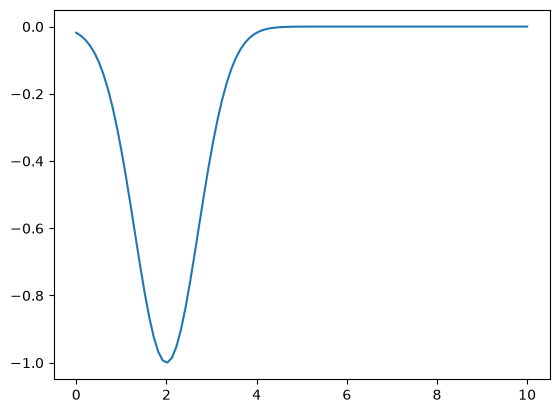

2.0202020202020203


In [3]:
y = np.linspace(0,10,100)
mp.plot(y,-np.exp(-(y-2)**2)); mp.show()
#print(max(y, key=lambda x: np.sinc(x-5)))

print(min(y, key=lambda x: -np.exp(-(x-2)**2)))

**Answer - why use `scipy.optimize` instead of `min(y, key=...)`?**

`min()` over a grid is a brute-force search: it can only return one of the grid points. Here the grid step is 10/99 ≈ 0.1, so it returns
**2.0202** after 100 evaluations, while `minimize_scalar` (Brent's method) returns **1.99999999** after only **10** evaluations.

* **Accuracy:** grid error ≈ step/2; to get 1e-8 you would need ~10^9 points. Optimisers iterate until a tolerance (`xtol`, `gtol`) is met.
* **Dimensionality:** a grid with k points per axis costs k^d evaluations (100 points in 10-D = 10^20). Gradient methods (BFGS, CG) scale with d.
* **Features:** bounds, equality/inequality constraints, use of gradients/Hessians, and a convergence report (`success`, `nit`, `nfev`).
* **Grid search still has a use:** a coarse grid is a cheap, robust way to find a *starting point* for a local optimiser on multimodal functions
  (`scipy.optimize.brute` does exactly that).

###Rosenbrock function

Now we optimize the infamous Rosenbrock function.

$f(x,y) = 0.5*(1-x)^2 + (y - x^2)^2$

In [4]:
def f(x):   # The rosenbrock function
    return .5*(1 - x[0])**2 + (x[1] - x[0]**2)**2
optimize.minimize(f, [0,-1], method="CG")

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 1.2743806081839638e-11
       x: [ 1.000e+00  1.000e+00]
     nit: 8
     jac: [-2.100e-07  2.518e-06]
    nfev: 48
    njev: 16

What happens if we change the seed to something very far from the solution point?

In [5]:
optimize.minimize(f, [200,-110], method="CG")

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 2.9893539643535623e-10
       x: [ 1.000e+00  1.000e+00]
     nit: 19
     jac: [ 6.787e-06  8.506e-06]
    nfev: 158
    njev: 52

**Answer - seed far from the solution.**

CG still converged to the minimum (1, 1), but it needed **19 iterations / 158 function evaluations** instead of **8 / 48**.

* This Rosenbrock variant has a **single minimum and no local minima**, so any seed eventually reaches it - only the cost grows.
  Far from the optimum the gradient is huge (f ≈ (y - x²)² ≈ 1.6·10^9 at (200, -110)) and the iterations first have to get into the
  curved, flat-bottomed valley `y ≈ x²`, where progress is slow.
* For **non-convex** functions a distant seed may end in a **different local minimum** or fail (overflow, `success=False`).
  Practical remedies: a good initial guess (physics, a coarse grid), several random starts, or global methods
  (`basinhopping`, `differential_evolution`, `shgo`), and scaling the variables to similar ranges.

**Constrained Optimization**

In this you need to give the constraints as well.

For example: $f(x) = 2xy + 2x - x^2 - 2 y^2$.

Constraints are as follows:

$x^3−y = 0$

$y−1 \geq 0$

In [6]:
def func(x, sign=1.0):
    """ Objective function """
    return sign*(2*x[0]*x[1] + 2*x[0] - x[0]**2 - 2*x[1]**2)

cons = ({'type': 'eq',
          'fun' : lambda x: np.array([x[0]**3 - x[1]])},
        {'type': 'ineq',
          'fun' : lambda x: np.array([x[1] - 1])})

res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),
                method='SLSQP', options={'disp': True})
print(res.x)

Optimization terminated successfully    (Exit mode 0)
            Current function value: -2.000000000000001
            Iterations: 4
            Function evaluations: 13
            Gradient evaluations: 4
[2.00000002 1.00000001]


In [7]:
res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),
                constraints=cons, method='BFGS', options={'disp': True})

print(res.x)

Optimization terminated successfully.
         Current function value: -2.000000
         Iterations: 6
         Function evaluations: 21
         Gradient evaluations: 7
[2.00000024 1.00000014]


/var/folders/mt/1q1ht4g51fz8t1y5sq38zbjr0000gn/T/ipykernel_49133/2128810766.py:1: RuntimeWarning: Method BFGS cannot handle constraints.
  res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),


In [8]:
# The cell with SLSQP above was called WITHOUT `constraints=cons`, and BFGS ignores constraints,
# so both returned the unconstrained optimum (2, 1). Passing the constraints to SLSQP:
res_con = optimize.minimize(func, [-1.0, 1.0], args=(-1.0,), constraints=cons,
                            method='SLSQP', options={'disp': True})
print(res_con.x, "-> f =", -res_con.fun)

Optimization terminated successfully    (Exit mode 0)
            Current function value: -1.0000001831248646
            Iterations: 9
            Function evaluations: 32
            Gradient evaluations: 9
[1.00000009 1.        ] -> f = 1.0000001831248646


**Note on the constrained example.** The first SLSQP call does not pass `constraints=cons`, and BFGS cannot handle constraints
(hence the `RuntimeWarning`), so both cells return the **unconstrained** maximum (2, 1), f = 2. With the constraints actually passed to SLSQP
the result is **(1, 1), f = 1**: on the curve y = x³ the function decreases for x ≥ 1, so the optimum lies on the boundary y = 1.
Always pick a method that supports constraints (`SLSQP`, `trust-constr`, `COBYLA`) and check that the constraints hold at `res.x`.

# Task 1 - Probability Distribution Function (PDF) of Sentinel data

**Data source.** Both missions are read from the free **Microsoft Planetary Computer** STAC catalogue
(no account needed, `planetary_computer.sign_inplace` adds a temporary anonymous token to each URL).
All assets are Cloud-Optimized GeoTIFFs, so `rasterio` reads **only the window covering the area of interest**
(~5 x 5 km, ~500 x 500 px) instead of downloading whole 800 MB tiles.

| | Natural area | Urban area |
|---|---|---|
| Location | Bialowieza Forest (primeval forest, NE Poland) | Warsaw city centre |
| Period | summer 2024 (Jun-Aug, leaf-on) | summer 2024 |

* **Sentinel-2 L2A** (surface reflectance): bands B02 (blue), B03 (green), B04 (red), B08 (NIR) - the four native 10 m bands.
  DN are converted to reflectance with `(DN - 1000) / 10000` (offset introduced in processing baseline 04.00).
  The scene is chosen by tile cloud cover **and** verified on the AOI with the Scene Classification Layer (SCL).
* **Sentinel-1 RTC** (radiometrically terrain-corrected gamma0, VV and VH, linear power, already in UTM).
  RTC is used instead of raw GRD because GRD is in radar (slant/ground-range) geometry and cannot be cut by a lat/lon box directly.
  The S1 acquisition closest in time to the S2 scene is used.

In [9]:
%pip install -q rasterio pystac-client planetary-computer shapely scikit-image

Note: you may need to restart the kernel to use updated packages.


In [10]:
import numpy as np
import matplotlib.pyplot as plt
import pystac_client
import planetary_computer
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
from shapely.geometry import box, shape
from scipy import stats

catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                    modifier=planetary_computer.sign_inplace)

REGIONS = {                       # [lon_min, lat_min, lon_max, lat_max]
    "natural": [23.82, 52.74, 23.90, 52.79],    # Bialowieza Forest
    "urban":   [20.96, 52.21, 21.03, 52.255],   # Warsaw centre
}
DATE_RANGE = "2024-06-01/2024-08-31"
S2_BANDS = {"B02": "blue", "B03": "green", "B04": "red", "B08": "NIR"}
SCL_INVALID = [0, 3, 8, 9, 10]    # no data, cloud shadow, cloud medium/high probability, thin cirrus


def read_window(href, bbox):
    """Read only the pixels of a COG that fall inside a lon/lat bounding box."""
    with rasterio.open(href) as src:
        window = from_bounds(*transform_bounds("EPSG:4326", src.crs, *bbox), src.transform)
        return src.read(1, window=window)


def items_covering(collection, bbox, **search_kwargs):
    """STAC items whose footprint fully contains the AOI (avoids tiles cut at the swath/tile edge)."""
    items = catalog.search(collections=[collection], bbox=bbox, datetime=DATE_RANGE, **search_kwargs).item_collection()
    aoi = box(*bbox)
    return [it for it in items if shape(it.geometry).contains(aoi)]


def best_s2_item(bbox, max_invalid=0.01):
    """Least cloudy S2 scene; tile cloud cover is only a hint, so the AOI is checked with the SCL band."""
    items = items_covering("sentinel-2-l2a", bbox, query={"eo:cloud_cover": {"lt": 20}})
    for it in sorted(items, key=lambda it: it.properties["eo:cloud_cover"]):
        invalid = np.isin(read_window(it.assets["SCL"].href, bbox), SCL_INVALID).mean()
        if invalid <= max_invalid:
            return it, invalid
    raise RuntimeError("no clear scene found")


def s2_reflectance(item, band, bbox):
    dn = read_window(item.assets[band].href, bbox).astype(np.float32)
    offset = -1000.0 if float(item.properties["s2:processing_baseline"]) >= 4.0 else 0.0
    return (dn + offset) / 10000.0


def s1_backscatter(item, pol, bbox):
    """Linear gamma0; nodata (-32768) and non-positive values become NaN."""
    img = read_window(item.assets[pol].href, bbox).astype(np.float32)
    img[img <= 0] = np.nan
    return img


s2, s1 = {}, {}
for region, bbox in REGIONS.items():
    item, invalid = best_s2_item(bbox)
    s2[region] = {"item": item, **{b: s2_reflectance(item, b, bbox) for b in S2_BANDS}}
    s1_item = min(items_covering("sentinel-1-rtc", bbox), key=lambda it: abs(it.datetime - item.datetime))
    s1[region] = {"item": s1_item, **{p: s1_backscatter(s1_item, p, bbox) for p in ("vv", "vh")}}
    print(f"{region:8s} S2: {item.id} (AOI invalid px: {invalid:.2%}), shape {s2[region]['B04'].shape}")
    print(f"{'':8s} S1: {s1_item.id} ({s1_item.properties['sat:orbit_state']}), shape {s1[region]['vv'].shape}")

natural  S2: S2B_MSIL2A_20240828T092549_R136_T34UFD_20240828T122710 (AOI invalid px: 0.00%), shape (577, 562)
         S1: S1A_IW_GRDH_1SDV_20240831T043622_20240831T043647_055452_06C39E_rtc (descending), shape (580, 564)


urban    S2: S2B_MSIL2A_20240814T094549_R079_T34UDC_20240814T123852 (AOI invalid px: 0.00%), shape (501, 478)
         S1: S1A_IW_GRDH_1SDV_20240815T161940_20240815T162005_055226_06BB60_rtc (ascending), shape (501, 478)


## 1.1 Sentinel-2 images
True-colour composites (B04, B03, B02) with a 2-98 % percentile stretch (a plain min-max stretch would be dominated by a few very bright pixels).

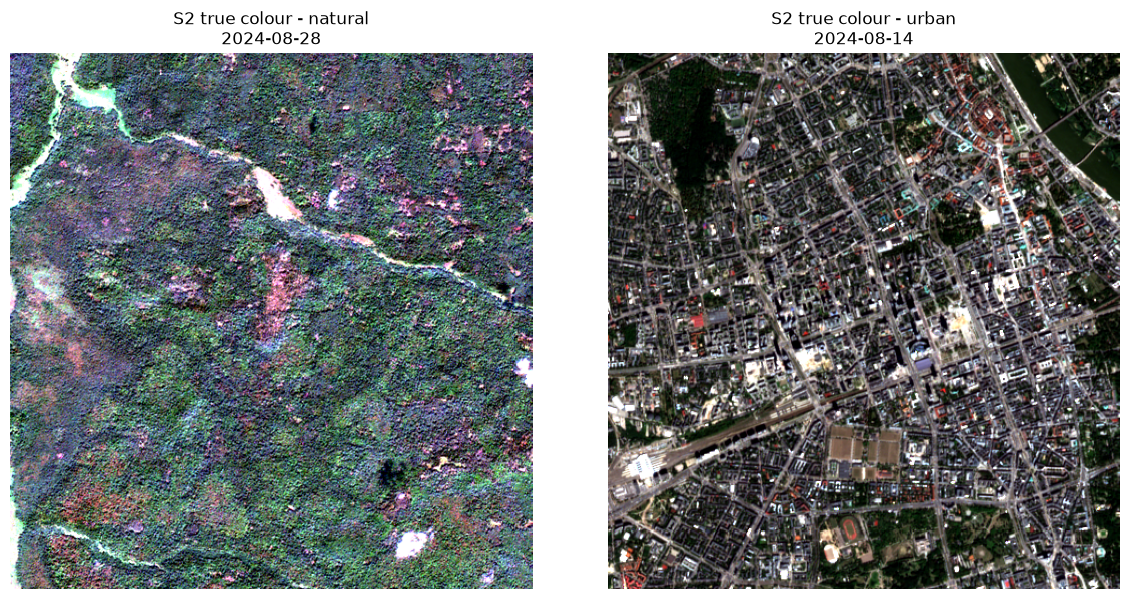

In [11]:
def stretch(img, lo=2, hi=98):
    """Percentile contrast stretch to [0, 1], per channel."""
    p_lo, p_hi = np.nanpercentile(img, [lo, hi], axis=(0, 1))
    return np.clip((img - p_lo) / (p_hi - p_lo), 0, 1)


rgb = {r: np.dstack([s2[r]["B04"], s2[r]["B03"], s2[r]["B02"]]) for r in REGIONS}

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, region in zip(axes, REGIONS):
    ax.imshow(stretch(rgb[region]))
    ax.set_title(f"S2 true colour - {region}\n{s2[region]['item'].datetime:%Y-%m-%d}")
    ax.axis("off")
plt.tight_layout(); plt.show()

## 1.2 Histograms (PDF estimates) of Sentinel-2 bands
`density=True` normalises the histogram so that its area equals 1 - it becomes an estimate of the PDF and
regions with different pixel counts can be compared directly. All histograms share the same bins.

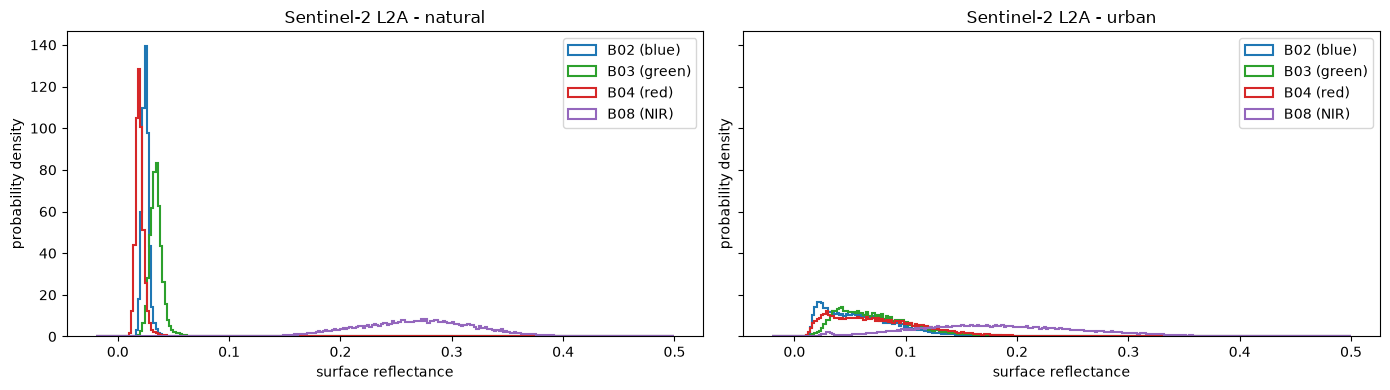

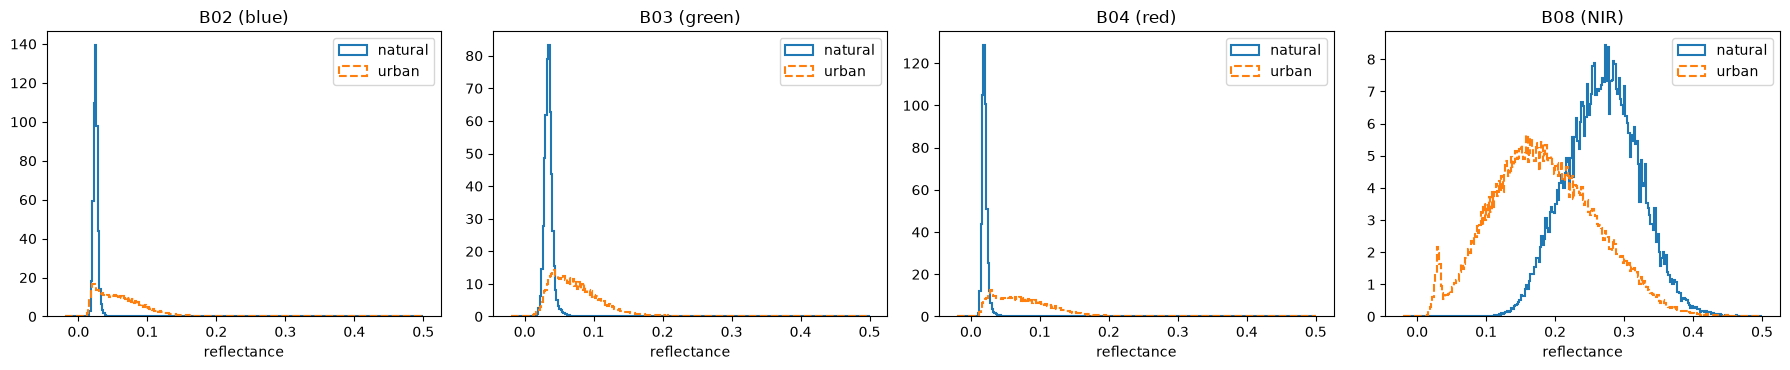

In [12]:
bins = np.linspace(-0.02, 0.5, 261)
colors = {"B02": "tab:blue", "B03": "tab:green", "B04": "tab:red", "B08": "tab:purple"}

# (a) spectral view: all bands of one region on one plot
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, region in zip(axes, REGIONS):
    for band, name in S2_BANDS.items():
        ax.hist(s2[region][band].ravel(), bins=bins, density=True, histtype="step", lw=1.5,
                color=colors[band], label=f"{band} ({name})")
    ax.set(title=f"Sentinel-2 L2A - {region}", xlabel="surface reflectance", ylabel="probability density")
    ax.legend()
plt.tight_layout(); plt.show()

# (b) region view: natural vs urban for each band
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, (band, name) in zip(axes, S2_BANDS.items()):
    for region, ls in zip(REGIONS, ["-", "--"]):
        ax.hist(s2[region][band].ravel(), bins=bins, density=True, histtype="step", lw=1.5, ls=ls, label=region)
    ax.set(title=f"{band} ({name})", xlabel="reflectance")
    ax.legend()
plt.tight_layout(); plt.show()

In [13]:
def describe(x):
    x = x[np.isfinite(x)].ravel()
    return dict(mean=x.mean(), std=x.std(), median=np.median(x), skew=stats.skew(x), kurt=stats.kurtosis(x))

print(f"{'region':8s} {'band':5s} {'mean':>7s} {'std':>7s} {'median':>7s} {'skew':>6s} {'kurt':>6s}")
for region in REGIONS:
    for band in S2_BANDS:
        d = describe(s2[region][band])
        print(f"{region:8s} {band:5s} {d['mean']:7.4f} {d['std']:7.4f} {d['median']:7.4f} {d['skew']:6.2f} {d['kurt']:6.2f}")
    ndvi = (s2[region]["B08"] - s2[region]["B04"]) / (s2[region]["B08"] + s2[region]["B04"])
    print(f"{region:8s} NDVI  mean = {np.nanmean(ndvi):.3f}\n")

region   band     mean     std  median   skew   kurt
natural  B02    0.0251  0.0039  0.0248   5.66  92.96
natural  B03    0.0346  0.0063  0.0342   1.96  14.50
natural  B04    0.0200  0.0047  0.0194   4.17  45.20
natural  B08    0.2689  0.0527  0.2696   0.09   0.01
natural  NDVI  mean = 0.858

urban    B02    0.0637  0.0430  0.0560   3.39  37.94
urban    B03    0.0763  0.0436  0.0679   2.94  27.64
urban    B04    0.0784  0.0500  0.0698   2.15  14.90
urban    B08    0.1848  0.0765  0.1803   0.41   1.02
urban    NDVI  mean = 0.390



### Observations - Sentinel-2

**Natural area (Bialowieza Forest)**
* Visible bands form **very narrow peaks at low reflectance**: blue ≈ 0.025, green ≈ 0.035, red ≈ 0.020 (std 0.004-0.006).
  Chlorophyll absorbs blue and red, so green is the highest visible band - the classic vegetation signature visible directly in the PDFs.
* **NIR is high (≈ 0.27) and broad**, almost **Gaussian** (skewness 0.09, excess kurtosis 0.01) - variability comes from canopy structure.
  NIR/red contrast gives mean **NDVI = 0.86** (dense, healthy forest).
* The visible bands have **high kurtosis (15-93) and positive skew**: the core is homogeneous canopy, the long right tail is a small fraction of
  meadows along the river, clearings and dead spruce stands (pink patches in the RGB).

**Urban area (Warsaw centre)**
* Visible bands are **~10x wider** (std 0.043-0.050) and shifted to higher values (0.06-0.08), **right-skewed** (skew 2-3.4):
  a mixture of dark shadows/asphalt, grey concrete and bright roofs.
* The **blue, green and red PDFs nearly overlap** - urban materials are spectrally flat ("grey"), unlike vegetation.
* NIR is lower (≈ 0.18) and broader; the small separate peak at ≈ 0.03 is **water** (Vistula), which absorbs NIR. NDVI = 0.39.

**Practical conclusions**
* The PDF shape is itself a feature: a single threshold on NIR or NDVI separates the classes; std / entropy of visible bands reflects
  heterogeneity (texture), which is high for cities.
* The distributions are **non-Gaussian, multimodal and heavy-tailed**, so for ML preprocessing robust scaling (percentiles, median/IQR)
  works better than mean/std z-scoring, and mixed pixels/rare classes live in the tails.
* An image histogram is a mixture of class-conditional PDFs - this is the basis of histogram thresholding (Otsu) and
  Gaussian-mixture / Bayesian classifiers.

## 1.3 Sentinel-1 (same regions)
SAR backscatter is shown both in **linear power** (what the sensor measures) and in **decibels** `10*log10(gamma0)`,
which is the standard way of analysing SAR intensities (it turns the multiplicative speckle into an additive term).

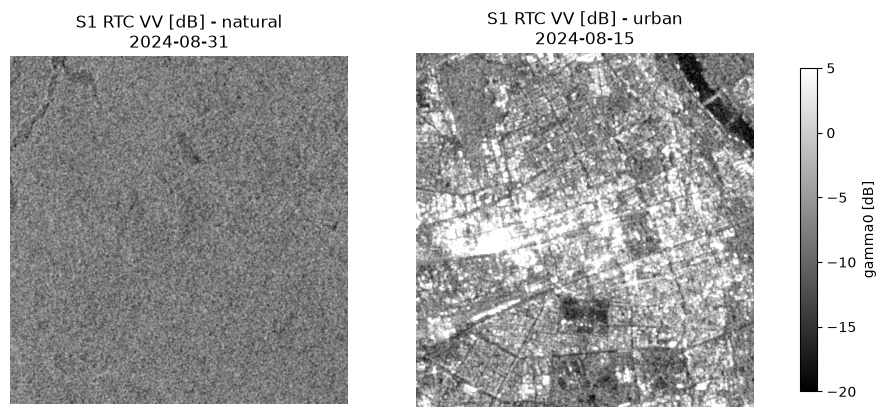

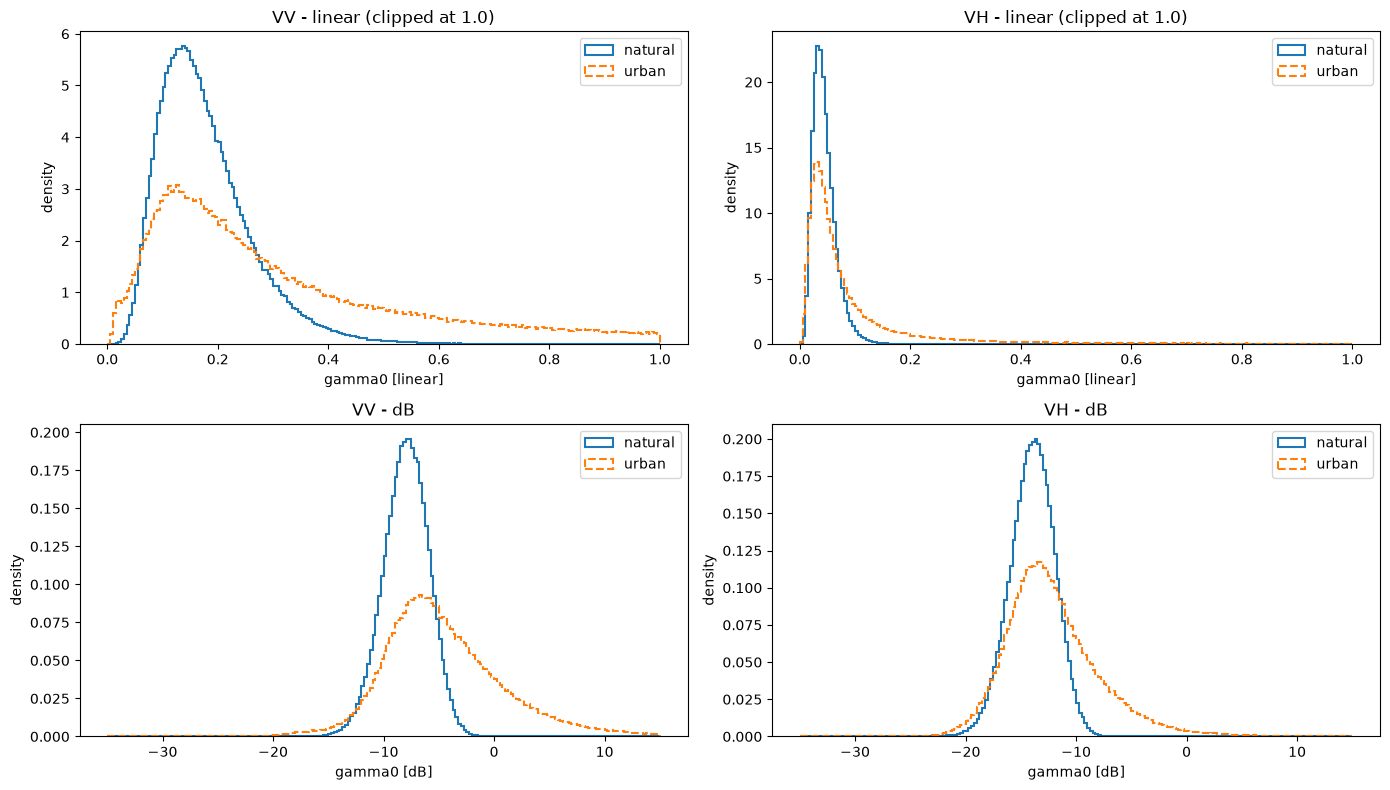

region   pol  mean dB  std dB  skew dB  CV lin skew lin  >0 dB
natural  vv     -7.98    2.05    -0.21    0.48     1.28   0.0%
natural  vh    -13.96    2.02    -0.20    0.47     1.25   0.0%
urban    vv     -4.45    5.67     1.06   21.03    63.93  18.0%
urban    vh    -12.11    4.28     1.05   10.62    76.83   1.4%


In [14]:
to_db = lambda x: 10 * np.log10(x)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, region in zip(axes, REGIONS):
    im = ax.imshow(to_db(s1[region]["vv"]), cmap="gray", vmin=-20, vmax=5)
    ax.set_title(f"S1 RTC VV [dB] - {region}\n{s1[region]['item'].datetime:%Y-%m-%d}")
    ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.7, label="gamma0 [dB]")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for col, pol in enumerate(["vv", "vh"]):
    for region, ls in zip(REGIONS, ["-", "--"]):
        x = s1[region][pol]
        x = x[np.isfinite(x)]
        axes[0, col].hist(x, bins=np.linspace(0, 1.0, 201), density=True, histtype="step", lw=1.5, ls=ls, label=region)
        axes[1, col].hist(to_db(x), bins=np.linspace(-35, 15, 201), density=True, histtype="step", lw=1.5, ls=ls, label=region)
    axes[0, col].set(title=f"{pol.upper()} - linear (clipped at 1.0)", xlabel="gamma0 [linear]", ylabel="density")
    axes[1, col].set(title=f"{pol.upper()} - dB", xlabel="gamma0 [dB]", ylabel="density")
    for ax in axes[:, col]:
        ax.legend()
plt.tight_layout(); plt.show()

print(f"{'region':8s} {'pol':3s} {'mean dB':>8s} {'std dB':>7s} {'skew dB':>8s} {'CV lin':>7s} {'skew lin':>8s} {'>0 dB':>6s}")
for region in REGIONS:
    for pol in ["vv", "vh"]:
        x = s1[region][pol][np.isfinite(s1[region][pol])]
        db = to_db(x)
        print(f"{region:8s} {pol:3s} {db.mean():8.2f} {db.std():7.2f} {stats.skew(db):8.2f} "
              f"{x.std() / x.mean():7.2f} {stats.skew(x):8.2f} {(db > 0).mean():6.1%}")

### Observations - Sentinel-1 (and comparison with Sentinel-2)

* **Linear scale:** both regions are strongly **right-skewed** (gamma-like). This is **speckle** - multiplicative noise from coherent
  imaging: intensity of a homogeneous target follows a gamma distribution with coefficient of variation CV = 1/sqrt(L).
  For the forest CV ≈ 0.48, i.e. **≈ 4.3 effective looks** of the RTC product. That is why SAR is analysed in **dB**, where the PDF becomes
  near-symmetric (forest skewness -0.2) and speckle becomes additive.
* **Natural (forest):** unimodal, narrow PDFs: **VV ≈ -8 dB, VH ≈ -14 dB, std ≈ 2 dB**. The spread is almost only speckle -
  the forest is a homogeneous **volume scatterer** (canopy), which also explains the relatively strong cross-pol VH return.
  Unlike S2, the image shows almost no internal structure (the river is barely visible).
* **Urban:** VV mean ≈ -4.5 dB with **std 5.7 dB** and a long **bright tail** (18 % of VV pixels above 0 dB, CV in linear scale ≈ 21).
  Walls and ground form **dihedral (double-bounce) reflectors** and metal structures act as point scatterers. The tail is weaker in **VH**
  because double bounce mostly preserves polarisation. The left tail is the dark, specular **river** and smooth surfaces (squares, parks).
* **S1 vs S2:** in S2 the classes differ mainly in the *location* of the PDFs (spectral signature); in S1 they differ mainly in **spread and
  tail** (scattering mechanism). VV dB std and the fraction of very bright pixels are simple, robust urban indicators, and they work
  regardless of clouds and daylight. Mean VH alone separates the two regions poorly (-14 vs -12 dB).
* **Caveat:** the S1 scenes come from different orbits (forest: descending, city: ascending). Urban backscatter depends on look direction
  vs. street orientation (cardinal effect), so for quantitative comparisons the same relative orbit should be used.

# Task 2 - Steganography (LSB replacement)

**Cover image:** the urban Sentinel-2 true-colour composite converted to **8-bit** (`uint8`, 3 channels) -
the form in which satellite images are typically distributed as quick-looks / PNG / JPEG.
The two least significant bits of **every channel of every pixel** are replaced with random values:

`stego = (cover & 0b11111100) | random_2_bits`

`& 0b11111100` clears bits 0-1, `|` writes the new bits. Bitwise operations are used instead of arithmetic
(e.g. `cover - cover % 4 + r`) because they are exact, cannot overflow `uint8`, and express the intent directly.
A seeded `np.random.default_rng` makes the experiment reproducible.

In [15]:
from skimage.metrics import structural_similarity, peak_signal_noise_ratio

cover = (stretch(rgb["urban"]) * 255).round().astype(np.uint8)

rng = np.random.default_rng(42)
payload = rng.integers(0, 4, size=cover.shape, dtype=np.uint8)      # 2 random bits per channel per pixel
stego = (cover & np.uint8(0b11111100)) | payload

diff = stego.astype(np.int16) - cover.astype(np.int16)
print(f"changed values      : {(diff != 0).mean():.1%}")
print(f"max |difference|    : {np.abs(diff).max()} grey levels (of 255)")
print(f"MSE                 : {np.mean(diff.astype(float) ** 2):.3f}")
print(f"PSNR                : {peak_signal_noise_ratio(cover, stego):.2f} dB")
print(f"SSIM                : {structural_similarity(cover, stego, channel_axis=-1):.4f}")

changed values      : 75.0%
max |difference|    : 3 grey levels (of 255)
MSE                 : 2.544
PSNR                : 44.08 dB
SSIM                : 0.9974


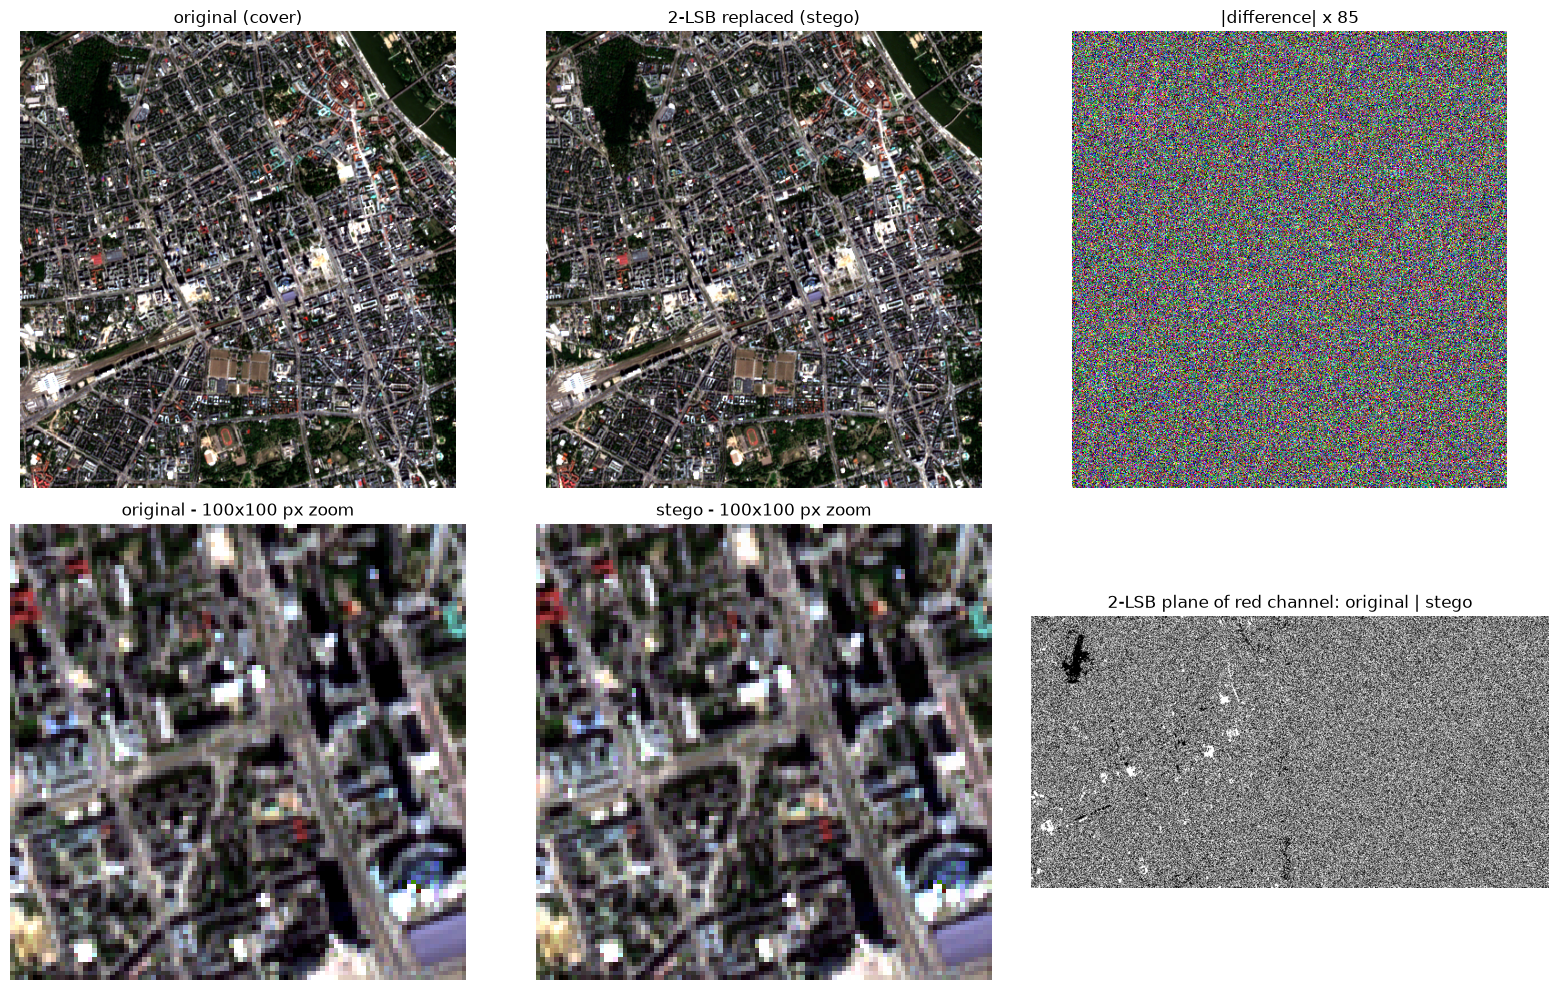

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes[0, 0].imshow(cover);  axes[0, 0].set_title("original (cover)")
axes[0, 1].imshow(stego);  axes[0, 1].set_title("2-LSB replaced (stego)")
axes[0, 2].imshow(np.abs(diff).astype(np.uint8) * 85); axes[0, 2].set_title("|difference| x 85")
zoom = (slice(200, 300), slice(200, 300))
axes[1, 0].imshow(cover[zoom], interpolation="nearest"); axes[1, 0].set_title("original - 100x100 px zoom")
axes[1, 1].imshow(stego[zoom], interpolation="nearest"); axes[1, 1].set_title("stego - 100x100 px zoom")
axes[1, 2].imshow(np.hstack([cover[..., 0] & 3, stego[..., 0] & 3]), cmap="gray")
axes[1, 2].set_title("2-LSB plane of red channel: original | stego")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

**Answer - visual quality.** **No visible difference**, even in the 100 x 100 px zoom. Each value changes by at most **3 of 255 levels**
(75 % of values change - the random bits match the old ones with probability 1/4), giving **PSNR ≈ 44 dB** and **SSIM ≈ 0.997**.
Differences below ~1-2 % of the range are under the visibility threshold, and PSNR > 40 dB is generally treated as visually lossless.
The amplified difference image is pure noise with no structure.
The **bit-plane image** does show a difference: in the original the 2 LSBs still carry some structure (saturated areas,
e.g. dark park and bright roofs, are constant), while in the stego image they are uniform noise. The manipulation is invisible
to the eye but not to statistics.

## 2.2 PDF of the original vs manipulated image
For 8-bit data the natural choice is **one bin per grey level** (`np.bincount`), otherwise wider bins would average out exactly the fine
structure that LSB embedding changes.

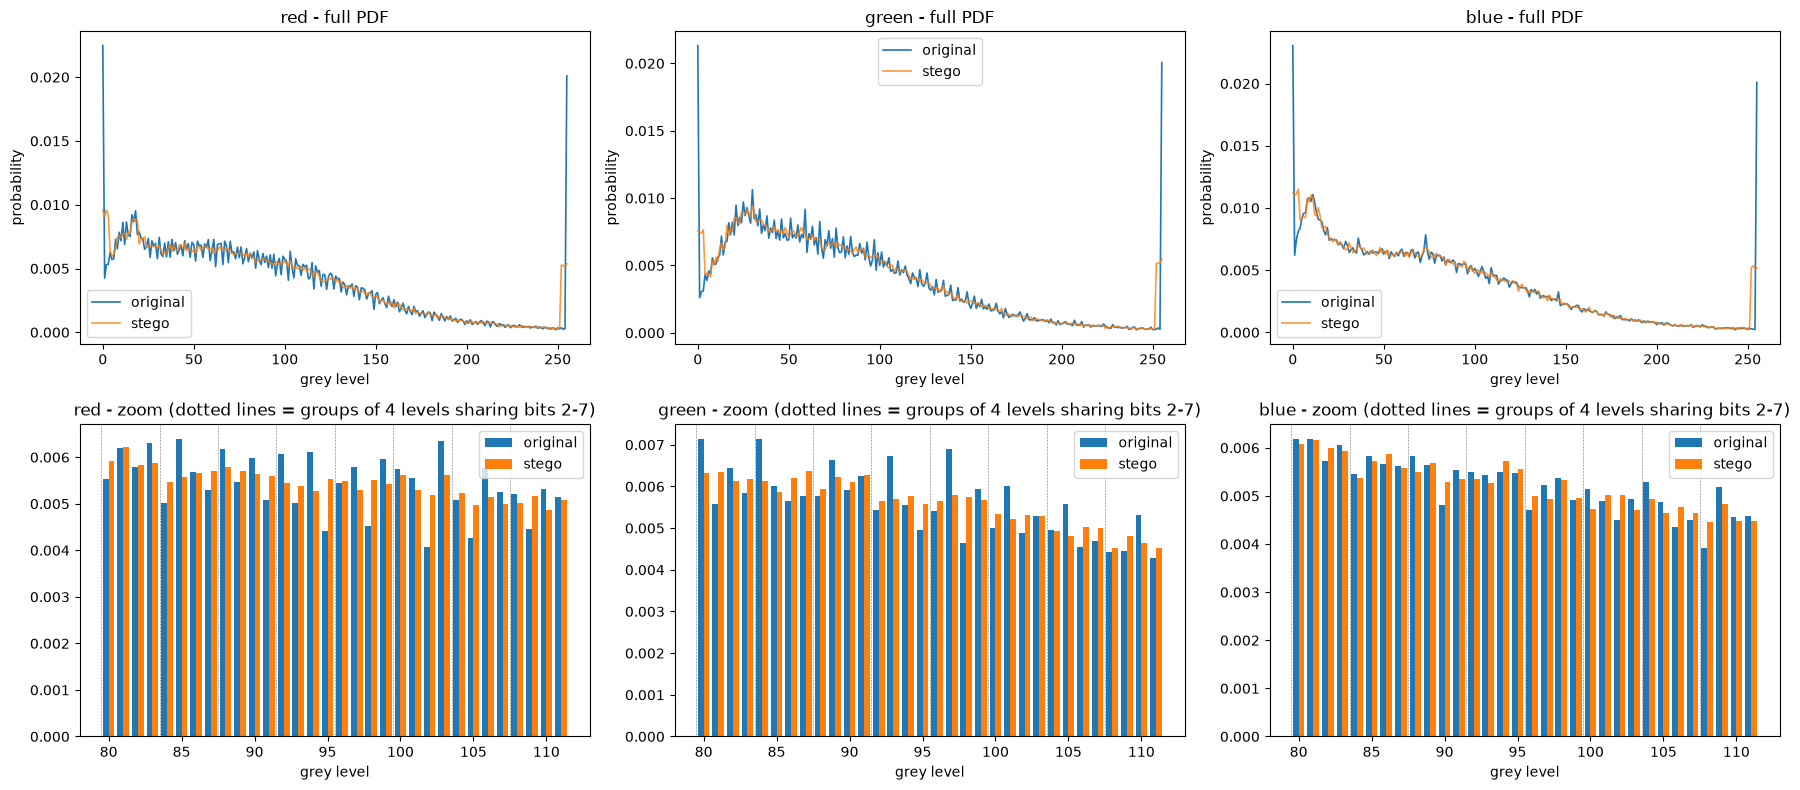

In [17]:
channel_names = ["red", "green", "blue"]
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for c, name in enumerate(channel_names):
    h_cov = np.bincount(cover[..., c].ravel(), minlength=256) / cover[..., c].size
    h_stg = np.bincount(stego[..., c].ravel(), minlength=256) / stego[..., c].size
    axes[0, c].plot(h_cov, label="original", lw=1.2)
    axes[0, c].plot(h_stg, label="stego", lw=1.2, alpha=0.8)
    axes[0, c].set(title=f"{name} - full PDF", xlabel="grey level", ylabel="probability")
    axes[0, c].legend()
    # zoom on 32 mid-tone grey levels (the 0/255 spikes from percentile clipping are visible in the full PDF)
    lv = np.arange(80, 112)
    axes[1, c].bar(lv - 0.2, h_cov[lv], width=0.4, label="original")
    axes[1, c].bar(lv + 0.2, h_stg[lv], width=0.4, label="stego")
    for b in lv[lv % 4 == 0]:
        axes[1, c].axvline(b - 0.5, color="k", lw=0.4, ls=":")
    axes[1, c].set(title=f"{name} - zoom (dotted lines = groups of 4 levels sharing bits 2-7)", xlabel="grey level")
    axes[1, c].legend()
plt.tight_layout(); plt.show()

### Can the histogram reveal the manipulation? - a simple statistical test
Random 2-LSB replacement keeps bits 2-7, so each group of 4 levels `{4k, ..., 4k+3}` keeps its total count, but inside the group
the counts become **equal on average** (uniform payload). A natural image has a smooth but *sloped* histogram, and stretched/quantised
data often has empty or over-filled levels ("combing"). The test below is a chi-square test of within-group uniformity (the idea of
the Westfeld-Pfitzmann attack, generalised from pairs of values to groups of 4):

* H0 = "the levels inside each group are equally likely" (= what embedding produces).
* very small p-value -> H0 rejected -> histogram looks **natural**; p-value ~ 0.5 -> histogram is **consistent with embedding**.

As a second check the same test is run on the **raw 16-bit Sentinel-2 DN** (B04, urban) before and after the same 2-LSB replacement.

In [18]:
def lsb_uniformity_test(img, n_bits=2, min_count=20):
    """Chi-square test that counts within each group of 2**n_bits consecutive levels are equal."""
    g = 2 ** n_bits
    h = np.bincount(img.ravel())
    h = np.pad(h, (0, (-len(h)) % g)).reshape(-1, g)
    h = h[h.mean(axis=1) >= min_count]                    # skip nearly empty groups (chi-square approximation)
    expected = h.mean(axis=1, keepdims=True)
    chi2 = ((h - expected) ** 2 / expected).sum()
    dof = h.shape[0] * (g - 1)
    return chi2 / dof, stats.chi2.sf(chi2, dof)


print("8-bit true colour (urban)")
for c, name in enumerate(channel_names):
    r_c, p_c = lsb_uniformity_test(cover[..., c])
    r_s, p_s = lsb_uniformity_test(stego[..., c])
    print(f"  {name:5s} original: chi2/dof = {r_c:6.2f}, p = {p_c:.2e}   |   stego: chi2/dof = {r_s:5.2f}, p = {p_s:.2f}")

dn = (s2["urban"]["B04"] * 10000 + 1000).round().astype(np.uint16)         # back to the original 16-bit DN
dn_stego = (dn & np.uint16(0xFFFC)) | rng.integers(0, 4, size=dn.shape, dtype=np.uint16)
print("\n16-bit raw DN, B04 (urban)")
for label, img in [("original", dn), ("stego", dn_stego)]:
    r, p = lsb_uniformity_test(img)
    print(f"  {label:8s}: chi2/dof = {r:5.2f}, p = {p:.2e}")
print(f"  PSNR of the 16-bit embedding: {peak_signal_noise_ratio(dn, dn_stego, data_range=int(dn.max()) - int(dn.min())):.1f} dB, "
      f"max change = 3 DN = 0.0003 reflectance")

8-bit true colour (urban)
  red   original: chi2/dof = 114.32, p = 0.00e+00   |   stego: chi2/dof =  1.14, p = 0.08
  green original: chi2/dof = 124.54, p = 0.00e+00   |   stego: chi2/dof =  0.99, p = 0.53
  blue  original: chi2/dof =  95.12, p = 0.00e+00   |   stego: chi2/dof =  1.15, p = 0.07

16-bit raw DN, B04 (urban)
  original: chi2/dof = 74.42, p = 0.00e+00
  stego   : chi2/dof =  1.06, p = 6.16e-02
  PSNR of the 16-bit embedding: 79.9 dB, max change = 3 DN = 0.0003 reflectance


**Answer - PDF of the original vs. manipulated image.**

* **Global shape is preserved** - bits 2-7 are unchanged, so the coarse histogram (and mean, std, any class threshold) stays the same.
* **The fine structure changes:**
  * the original 8-bit histogram has a **comb pattern** (some levels systematically more frequent) caused by the contrast stretch
    from ~12-bit data to 256 levels; after embedding the histogram becomes **flat inside every group of 4 levels**
    (a staircase pattern) and the comb disappears;
  * the **saturation spikes at 0 and 255** (2 % percentile clipping) are spread into four equal bars at 0-3 and 252-255 - an obvious
    fingerprint, because a clip-stretch can only produce values exactly at 0 and 255.
* **Statistical test:** chi²/dof ≈ 95-125 for the original (p ≈ 0, histogram is not group-uniform) vs. **≈ 1.0 for the stego image**
  (p > 0.05, consistent with random LSBs). The same holds for raw 16-bit S2 DN (74 vs 1.06), even though there the embedding is
  completely invisible (PSNR ≈ 80 dB, change ≤ 0.0003 reflectance, below the sensor noise).

**Can this be used to detect manipulation?** **Yes, for this kind of manipulation** - full-capacity LSB *replacement* leaves a clear
histogram fingerprint detectable without the original image. Limitations:
* With a small payload (only a few % of pixels changed) or **±1 embedding (LSB matching)** the histogram stays smooth and the
  test fails; stronger steganalysis (RS analysis, sample-pair analysis, rich models with an ensemble classifier, CNN steganalysers)
  is needed.
* A histogram only detects *pixel-statistics* changes; content changes such as copy-move or spliced objects require spatial/forensic
  methods.
* In EO practice, integrity is best ensured cryptographically: Sentinel SAFE products contain per-file **checksums** in
  `manifest.safe`, and hashes/digital signatures at distribution. Histogram analysis is a **forensic** tool when that chain of custody is missing.

# Task 3 (optional) - Compressive sensing
The original compressive-sensing code from the lab is run below unchanged, followed by an improved solver and notes on EO use.

## COMPRESSIVE SENSING

Now lets discuss about compressive sensing. Lets assume that we have some signal recorded (following Nyquist rate); lets call it $x$. Its size is $N$.

In the following signal we are using 500 samples and two sinusoids. You can note that one of them takes 10 samples per cycle; hence there are 50 cycles. So Nyquist will want us to have at least 100 samples in order to be able to know whats in the signal!

However if we look the signal through DCT then there are just two samples. Mark that we are using DCT and not FFT; because then we dont have to deal with complex numbers!



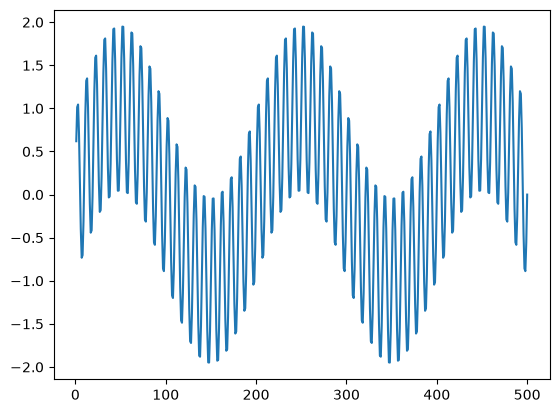

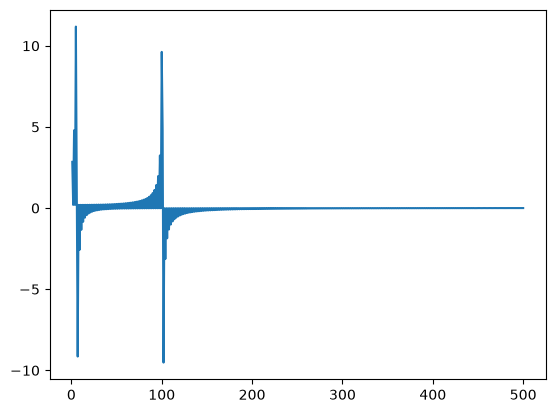

([<matplotlib.lines.Line2D at 0x11d392510>], None)

In [19]:
n = np.linspace(1,500,500)

#two harmonics signal
xx = np.sin(2*np.pi*n/10) + np.sin(2*np.pi*n/200)  #+ np.sin(2*np.pi*n/50)
mp.plot(n,xx), mp.show()
mp.plot(n,fftpack.dct(xx, norm='ortho')), mp.show()

**Sparse Sampling** \\
Lets assume that we only consider $n$ of this ($n \ll N$).

For this lets define a sparsifying vector sp which has only $n$ 1's and rest zeros placed in random places.

So sparsed data $xp = xx*sp$.

The trick is that these $n$ samples are randomly taken.

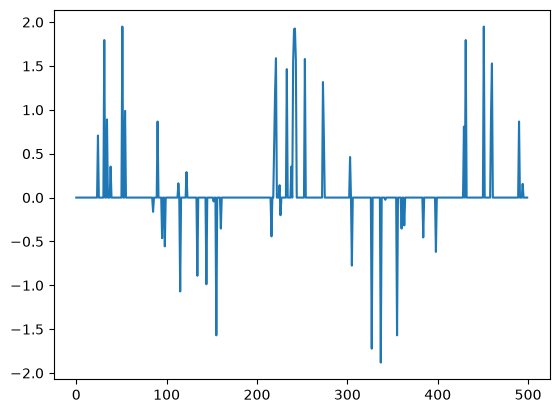

([<matplotlib.lines.Line2D at 0x11d3f0fb0>], None)

In [20]:
N = len(xx) #length of actual N
n = 50 #number of nonzero samples in our sparse signal
sp = np.array([1] * n + [0] * (N-n)) #n 1's and (N-n) 0's
np.random.shuffle(sp)

xp = xx*sp
mp.plot(xp), mp.show()

### Using Optimization
The trick of compressive sensing is that we try to use optimization in order to know the unknown from what is known!

So let us think what we know.

1- We know $xp$  the random-subNyquist-sampled signal and $sp$.

2- We know that the signal is sparse in DCT domain.

So lets try to look into the DCT domain. Lets assume that the DCT of the signal is $XX$. So IDCT of it should give us $xp$ back.

Lets define an optimization problem to do this.

What are the DCT samples that will give rise to a time domain signal which has the values of $xp$ at $sp$ time-indices. \\
We start with an intial estimate $XX$ which we will update in each iteration. \\
The cost function will be Euclidean distance between $xp$ and IDCT of $XX$.

         Current function value: 0.000001
         Iterations: 3
         Function evaluations: 30573
         Gradient evaluations: 61


/Users/wiktoria/workspace/MLforSpaceApplications/LAB2/.venv/lib/python3.12/site-packages/scipy/optimize/_minimize.py:779: OptimizeWarning: Desired error not necessarily achieved due to precision loss.
  res = _minimize_bfgs(fun, x0, args, jac, callback, **options)


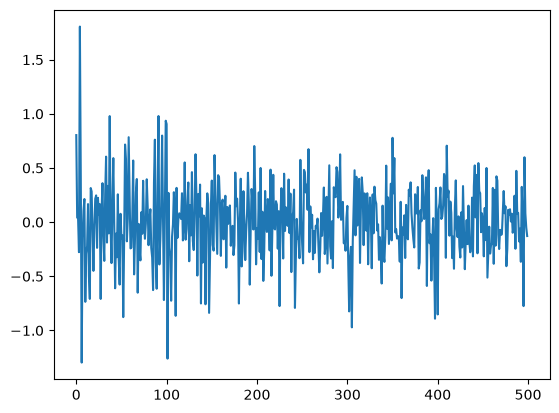

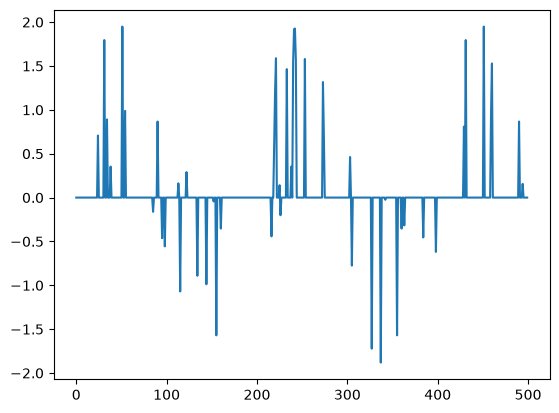

([<matplotlib.lines.Line2D at 0x11b87af60>], None)

In [21]:

XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    xd = fftpack.idct(XX, norm='ortho') #derived x from X
    xdn = xd*sp
    return np.linalg.norm((xdn - xp), ord=2)

seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, options={'disp': True})

xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Redfining the Optimization
Hmmmm. Enen though the optimization has not finished doing its job if we look at the result we seem to have achieved what we asked for!

The reconstructed signal $xrecon$ looks exactly like $xp$. So we did achieve what we wanted (theoritically speaking) but we want more.

What else can we do?

Lets add a condition that we want to optimize $||xrecon - xp ||$ but we also want to keep XX sparse, i.e. the $L0$ norm of $XX$ should be less than $n$.

Iteration limit reached    (Exit mode 9)
            Current function value: 1.755332316320841e-05
            Iterations: 100
            Function evaluations: 51282
            Gradient evaluations: 101


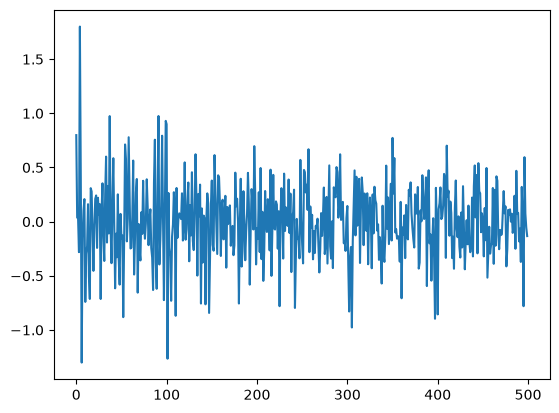

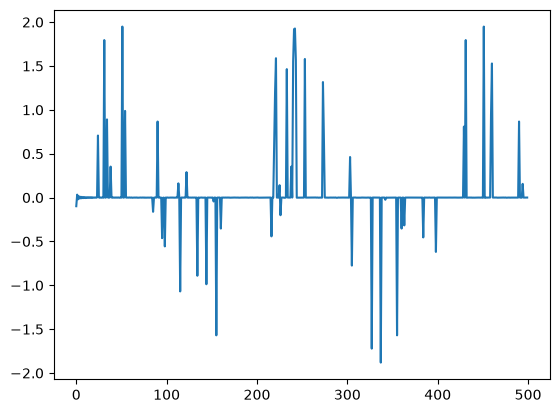

([<matplotlib.lines.Line2D at 0x11cbba990>], None)

In [22]:
XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    xd = fftpack.idct(XX, norm='ortho') #derived x from X
    xdn = xd*sp
    return np.linalg.norm((xdn - xp), ord=2)

cons = ({'type': 'ineq',
          'fun' : lambda XX: n - np.linalg.norm(XX,ord=0)})

#seed = np.random.rand(N)
seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, constraints=cons, options={'disp': True})

xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Re-redfining the Optimization: L1 Magic!!
Hmmmm. It seems its not working the way we want it to work. What else can we do?

It seems achieving $xrecon = xp$ is an easy task, because its sparse anyway.

So lets keep this as a condition (instead of making it the cost-function). And minimize $XX$. And let us use $L1$ norm here so as to keep the error under control. Remember that even though $L2$ norm is smooth, it has a square and blows up the error. So in wildly uknown problems like what we dealing with here, its better to use $L1$ norm.

In [23]:
XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    return np.linalg.norm(XX, ord=1)

cons = ({'type': 'eq',
          'fun' : lambda XX : np.linalg.norm(xp - fftpack.idct(XX, norm='ortho')*sp, ord = 2)})

seed = np.random.rand(N)
#seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, constraints=cons, options={'disp': True})

Iteration limit reached    (Exit mode 9)
            Current function value: 59.102607563987256
            Iterations: 100
            Function evaluations: 50929
            Gradient evaluations: 101


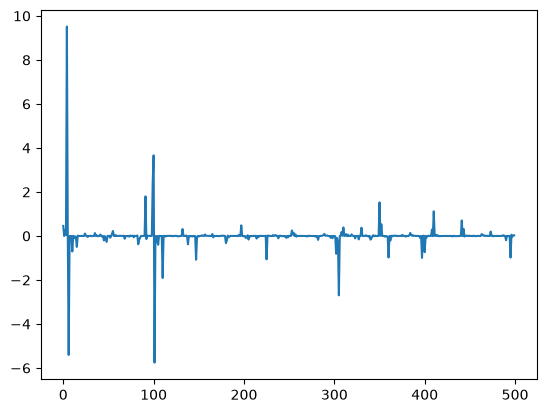

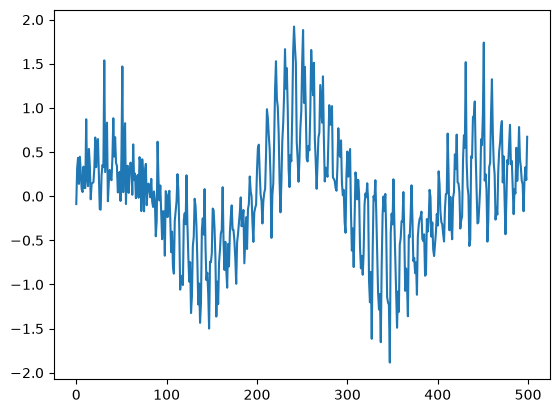

([<matplotlib.lines.Line2D at 0x11c996510>], None)

In [24]:
xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Conclusion
Unfortunately the optimization process did not end. We need more iteration. However, we seem to have got something which looks pretty much like the signal we have started with. It is noisy but it is encouraging given the fact that we have got only half the number of samples as Nyquist would have wanted.

This is the starting of Compressive Sensing (CS). We have learnt two things.

1- It is easy to cheat Nyquist if the signal is sparse in some other linearly transferable domain. 2- Redefining the optimization problem can help us achieve magical results.

The hard-core CS involvs more interesting objective functions and constraints to achieve even more interesting magical results.

### Basis pursuit as a linear program
The last formulation (min L1 subject to a non-smooth equality constraint) is
solved with a generic gradient-based solver and stops at the iteration limit. The **same problem (basis pursuit)** can be written as a
**linear program**, which a dedicated LP solver (HiGHS via `scipy.optimize.linprog`) solves exactly in a fraction of a second:

$\min \|s\|_1 \;\; \text{s.t.}\;\; A s = y, \quad A = (\text{rows of the IDCT matrix at the sampled indices}),\; s = u - v,\; u, v \ge 0$

samples used: 50 of 500  (10%)
basis pursuit (LP): 0.02 s, relative error = 0.417, non-zero DCT coeffs (|s|>1e-3) = 50
generic minimize  : relative error = 0.603


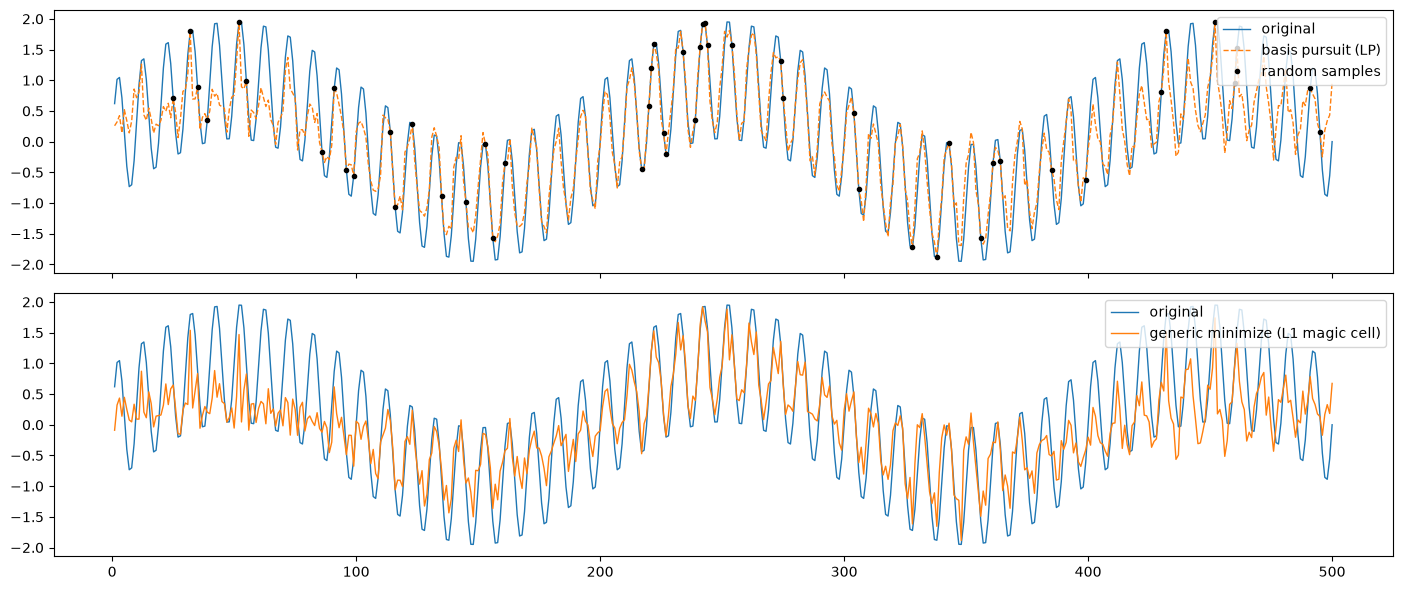

In [25]:
import time
from scipy.optimize import linprog

t_axis = np.arange(1, N + 1)                              # `n` was overwritten by the sample count above
idx = np.flatnonzero(sp)                                  # the same random sampling pattern as above
Psi = fftpack.idct(np.eye(N), norm='ortho', axis=0)       # x = Psi @ s  (columns = DCT basis vectors)
A, y = Psi[idx, :], xx[idx]

t0 = time.time()
lp = linprog(c=np.ones(2 * N), A_eq=np.hstack([A, -A]), b_eq=y, bounds=(0, None), method="highs")
s_bp = lp.x[:N] - lp.x[N:]
x_bp = Psi @ s_bp
t_bp = time.time() - t0

rel_err = lambda est: np.linalg.norm(est - xx) / np.linalg.norm(xx)
print(f"samples used: {len(idx)} of {N}  ({len(idx) / N:.0%})")
print(f"basis pursuit (LP): {t_bp:.2f} s, relative error = {rel_err(x_bp):.3f}, non-zero DCT coeffs (|s|>1e-3) = {(np.abs(s_bp) > 1e-3).sum()}")
print(f"generic minimize  : relative error = {rel_err(xrecon):.3f}")

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(t_axis, xx, label="original", lw=1); axes[0].plot(t_axis, x_bp, "--", label="basis pursuit (LP)", lw=1)
axes[0].plot(t_axis[idx], y, "k.", label="random samples"); axes[0].legend(loc="upper right")
axes[1].plot(t_axis, xx, label="original", lw=1); axes[1].plot(t_axis, xrecon, label="generic minimize (L1 magic cell)", lw=1)
axes[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

### How many samples are really needed?
CS guarantees recovery only for signals that are **sparse** (or compressible) in the chosen basis. The two sines do not fall exactly on
DCT basis frequencies/phases, so their energy leaks into many coefficients. Below: how many DCT coefficients hold 99 % of the energy,
the reconstruction error vs. number of random samples (median of 5 random patterns), and - for contrast - a signal that is
*exactly* 2-sparse in the DCT domain.

DCT coefficients holding 99% of the energy: 30 (of 500)
m =  25 (  5%):  two sines error = 0.901   exactly 2-sparse error = 3.0e-14


m =  50 ( 10%):  two sines error = 0.556   exactly 2-sparse error = 1.3e-14


m = 100 ( 20%):  two sines error = 0.316   exactly 2-sparse error = 7.3e-16


m = 150 ( 30%):  two sines error = 0.172   exactly 2-sparse error = 1.5e-15


m = 200 ( 40%):  two sines error = 0.095   exactly 2-sparse error = 3.7e-16


m = 250 ( 50%):  two sines error = 0.052   exactly 2-sparse error = 3.2e-16


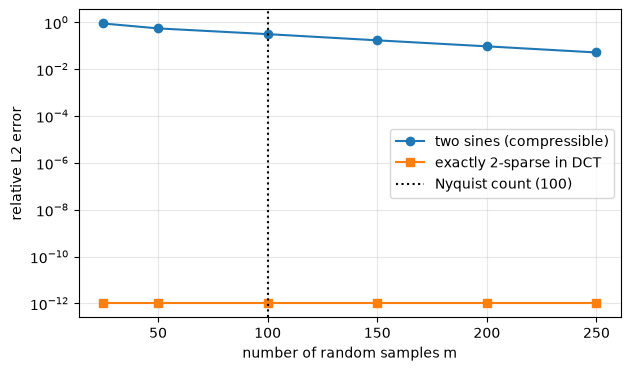

In [26]:
def basis_pursuit(idx, y):
    A = Psi[idx, :]
    res = linprog(c=np.ones(2 * N), A_eq=np.hstack([A, -A]), b_eq=y, bounds=(0, None), method="highs")
    return Psi @ (res.x[:N] - res.x[N:])

energy = np.sort(fftpack.dct(xx, norm='ortho') ** 2)[::-1].cumsum() / np.sum(xx ** 2)
print(f"DCT coefficients holding 99% of the energy: {np.searchsorted(energy, 0.99) + 1} (of {N})")

x_sparse = Psi[:, 100] * 10 + Psi[:, 5] * 10        # exactly 2 non-zero DCT coefficients
rng_cs = np.random.default_rng(0)
m_values = [25, 50, 100, 150, 200, 250]
err_xx, err_sparse = [], []
for m in m_values:
    e1, e2 = [], []
    for _ in range(5):
        idx_m = np.sort(rng_cs.choice(N, m, replace=False))
        e1.append(rel_err(basis_pursuit(idx_m, xx[idx_m])))
        e2.append(np.linalg.norm(basis_pursuit(idx_m, x_sparse[idx_m]) - x_sparse) / np.linalg.norm(x_sparse))
    err_xx.append(np.median(e1)); err_sparse.append(np.median(e2))
    print(f"m = {m:3d} ({m / N:4.0%}):  two sines error = {err_xx[-1]:.3f}   exactly 2-sparse error = {err_sparse[-1]:.1e}")

plt.figure(figsize=(7, 4))
plt.semilogy(m_values, err_xx, "o-", label="two sines (compressible)")
plt.semilogy(m_values, np.maximum(err_sparse, 1e-12), "s-", label="exactly 2-sparse in DCT")
plt.axvline(100, color="k", ls=":", label="Nyquist count (100)")
plt.xlabel("number of random samples m"); plt.ylabel("relative L2 error"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

**Answer - compressive sensing and where it is useful in EO.**

**What the experiments show**
* The generic `optimize.minimize` versions (cells above) either fit the samples without recovering the signal (L2 cost - infinitely many
  solutions match 50 samples) or stop at the iteration limit (L1 cost with a non-smooth equality constraint). The L1 formulation is the
  right idea, but it needs a suitable solver: written as a **linear program** the same problem is solved exactly in **~0.02 s**.
* Even the exact solution is poor with 50 samples (10 %), because the test signal is only **compressible**, not sparse: ~30 DCT coefficients
  carry 99 % of its energy (leakage of off-grid sinusoids). The error falls steadily with m, and a signal that is **exactly 2-sparse** is recovered
  **perfectly from 25 random samples** - 1/4 of the Nyquist count. Rule of thumb: m ≈ C·K·log(N/K) samples for a K-sparse signal.
  **Choosing a basis in which the data are really sparse matters more than the solver.**

**Where it is useful in Earth Observation**
* **On-board acquisition/compression** - downlink is the bottleneck of modern missions; CS moves complexity from the satellite
  (simple random projections, cheap encoder) to the ground (reconstruction).
* **Hyperspectral and single-pixel / coded-aperture imagers** (e.g. CASSI) - measuring a 3-D data cube with a 2-D detector and fewer
  measurements; sparse in wavelet/spectral dictionaries.
* **SAR** - reduced sampling or PRF, raw-data compression, and especially **SAR tomography (TomoSAR)**: reconstructing the vertical
  scattering profile (building/forest height) from a few irregular passes - a sparse inverse problem.
* **Gap filling / inpainting** - clouds, Landsat-7 SLC-off stripes, missing time-series epochs: missing pixels are random "unsampled"
  entries of a signal that is sparse in time or space.
* **Super-resolution and radio interferometry** (e.g. SMOS synthetic-aperture radiometer), with a sparsity prior on the scene.

Limits: reconstruction is iterative and costly for large images, needs random (incoherent) sampling and a basis where the scene is
sparse, and errors appear as artefacts rather than plain noise - important when the product is used quantitatively.